In [2]:
#包含全部函数，这些函数经过检验。
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq, fftshift
from scipy.interpolate import CubicSpline
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS', 'DejaVu Sans', 'Arial', 'Liberation Sans', 'Noto Sans CJK SC']
plt.rcParams['axes.unicode_minus'] = False

def myFFTAlgebra(x, y, T=None):
    """
    对周期信号进行傅里叶分析（FFT 和手动级数两种方法）
    参数
    ----------
    x : 1D ndarray
        等间距采样时间点，应覆盖一个完整周期 [0, T)（不含右端点）
    y : 1D ndarray
        与 x 对应的信号值
    T : float, optional
        信号周期。若为 None，则根据 x 自动计算（假设采样均匀且区间结束于 T 之前）
    返回
    -------
    result : dict
        包含两种方法的结果字典，结构如下：
        {
          'fft': {
              'freq': ndarray,          # 正频率分量（包含直流和 Nyquist）
              'amplitude': ndarray,     # 单边幅度谱
              'phase': ndarray          # 相位（弧度，对应余弦形式 cos(2πft + φ)）
          },
          'manual': {
              'freq': ndarray,          # 频率（k/T）
              'amplitude': ndarray,     # 幅度 sqrt(a_k² + b_k²)
              'phase': ndarray,         # 相位 arctan2(-b_k, a_k)
              'cos_coef': ndarray,      # 余弦系数 a_k（k=0,1,...,Nyquist）
              'sin_coef': ndarray,      # 正弦系数 b_k（b_0 = 0, b_Nyquist = 0）
              'reconstructed': ndarray  # 使用 a,b 重建的信号
          }
        }
    """
    x = np.asarray(x).flatten()
    y = np.asarray(y).flatten()
    N = len(x)
    if N != len(y):
        raise ValueError("x 和 y 长度必须相同")
    # 自动确定周期 T（假设采样均匀且覆盖 [0, T)）
    if T is None:
        dx = x[1] - x[0] if N > 1 else 1.0
        T = x[-1] + dx          # 最后一个采样点 + 采样间隔
    # ========== 方法1：NumPy FFT（单边谱）==========
    fft_vals = np.fft.fft(y) / N          # 双边谱（已归一化）
    freqs_fft = np.fft.fftfreq(N, d=T/N)  # 双边频率
    # 取单边正频率（0 到 Nyquist）
    pos_idx = np.arange(0, N//2 + 1)
    freqs_single = freqs_fft[pos_idx]
    fft_single = fft_vals[pos_idx]
    # 幅度：单边谱时，除直流外乘以 2
    amp_single = np.abs(fft_single)
    amp_single[1:-1] *= 2   # 对非直流且非 Nyquist 的频率加倍
    # 相位（直接来自 FFT 的辐角）
    phase_single = np.angle(fft_single)

    # 从 FFT 单边谱转换为余弦/正弦系数 a, b
    # 关系：A cos(2πft + φ) = A cosφ cos(2πft) - A sinφ sin(2πft)
    # 因此 a = A cosφ, b = -A sinφ
    a_fft = amp_single * np.cos(phase_single)
    b_fft = -amp_single * np.sin(phase_single)
    # 直流分量和 Nyquist 分量（如果存在）的 b 系数应为 0（理论上），但保留计算值
    # 若需要严格为 0，可强制设定：
    # b_fft[0] = 0.0
    # if N % 2 == 0:  # 偶数个点，存在 Nyquist 频率
    #     b_fft[-1] = 0.0
    
    # ========== 方法2：手动傅里叶级数系数 ==========
    # 确定最高谐波次数
    if N % 2 == 1:          # 奇数个点，最高谐波 (N-1)/2
        K = (N - 1) // 2
        nyquist = False
    else:                   # 偶数个点，最高谐波 N/2 (Nyquist)
        K = N // 2
        nyquist = True

    a = np.zeros(K + 1)     # cos 系数
    b = np.zeros(K + 1)     # sin 系数

    for k in range(K + 1):
        if k == 0:
            a[k] = np.mean(y)          # 直流分量 = 平均值
            b[k] = 0.0
        elif nyquist and k == K:       # Nyquist 频率（只有余弦项）
            a[k] = (1.0 / N) * np.sum(y * np.cos(2 * np.pi * k * x / T))
            b[k] = 0.0
        else:
            a[k] = (2.0 / N) * np.sum(y * np.cos(2 * np.pi * k * x / T))
            b[k] = (2.0 / N) * np.sum(y * np.sin(2 * np.pi * k * x / T))
    freqs_manual = np.arange(K + 1) / T
    # 幅度与相位（余弦形式：a cos + b sin = A cos(2πft + φ)）
    amp_manual = np.sqrt(a**2 + b**2)
    phase_manual = np.arctan2(-b, a)   # 注意负号，使得 cos(2πft + φ) 展开为 a cos - b sin
    # 重建信号
    y_recon = np.zeros_like(x)
    for i, t in enumerate(x):
        for k in range(K + 1):
            y_recon[i] += a[k] * np.cos(2 * np.pi * k * t / T) + b[k] * np.sin(2 * np.pi * k * t / T)

    # ========== 输出结果 ==========
    result = {
        'fft': {
            'freq': freqs_single,
            'amplitude': amp_single,
            'phase': phase_single,
            'cos_coef': a_fft,
            'sin_coef': b_fft,
            'cycle': T,
            'X':x
        },
        'manual': {
            'freq': freqs_manual,
            'amplitude': amp_manual,
            'phase': phase_manual,
            'cos_coef': a,
            'sin_coef': b,
            'reconstructed': y_recon,
            'cycle': T,
            'X' : x
        }
    }
    return result

def myFFTMatrix(y, start_time=0,T=None):
    """
    使用傅里叶矩阵（最小二乘法）对周期信号进行傅里叶级数分解。
    返回频率、幅度、相位，以及余弦系数 a 和正弦系数 b。

    参数
    ----------
    y : np.ndarray
        一维信号数组，假设在区间 [0, T) 上等间距采样（不含右端点）。
    T : float, optional
        信号周期。若为 None，则 T = len(y)（采样间隔为 1）。

    返回
    -------
    result : dict
        {
            'freq': ndarray,          # 频率数组 [0, 1/T, 2/T, ..., K/T]
            'amplitude': ndarray,     # 幅度谱（单边，对应余弦形式 A*cos(2πft + φ)）
            'phase': ndarray,         # 相位谱（弧度，范围 -π 到 π）
            'cos_coef': ndarray,      # 余弦系数 a_k（k=0,1,...,K）
            'sin_coef': ndarray,      # 正弦系数 b_k（k=0,1,...,K，其中 b_0=0，Nyquist 处 b=0）
            'reconstructed': ndarray, # 使用系数重建的信号
        }
    """
    y = np.asarray(y).flatten()
    N = len(y)
    if T is None:
        T = float(N)          # 默认周期等于采样点数（采样间隔为1）
    # 等间距时间点（不包含右端点，保证周期性）
    x = np.linspace(start_time, start_time + T, N, endpoint=False)
    w = 2 * np.pi / T         # 基频

    # 确定傅里叶级数的最高次数 K
    if N % 2 == 1:            # 奇数个点
        K = (N - 1) // 2
        cos_freqs = np.arange(0, K + 1)          # 0,1,...,K
        sin_freqs = np.arange(1, K + 1)          # 1,2,...,K
    else:                     # 偶数个点
        K = N // 2
        cos_freqs = np.arange(0, K + 1)          # 0,1,...,K
        sin_freqs = np.arange(1, K)              # 1,2,...,K-1

    # 构造傅里叶矩阵 mat
    mat = np.empty((N, 0))
    for k in cos_freqs:
        mat = np.column_stack((mat, np.cos(k * w * x)))
    for k in sin_freqs:
        mat = np.column_stack((mat, np.sin(k * w * x)))

    # 最小二乘法求解系数（mat 是方阵时等价于线性方程组求解）
    # 使用 lstsq 更稳定，但原代码用 inv，这里保留原风格也可，改为 lstsq 更鲁棒
    c, _, _, _ = np.linalg.lstsq(mat, y, rcond=None)   # 系数向量

    # 分离余弦系数 a 和正弦系数 b（注意长度可能不同）
    a_raw = c[:len(cos_freqs)]        # 对应 cos_freqs 顺序
    b_raw = c[len(cos_freqs):]        # 对应 sin_freqs 顺序

    # 构造完整的 a_k, b_k 数组（k = 0 .. K）
    a_full = np.zeros(K + 1)
    b_full = np.zeros(K + 1)

    # 填充余弦系数
    for idx, k in enumerate(cos_freqs):
        a_full[k] = a_raw[idx]
    # 填充正弦系数（sin_freqs 中的 k 从 1 开始）
    for idx, k in enumerate(sin_freqs):
        b_full[k] = b_raw[idx]

    # 频率数组
    freqs = np.arange(K + 1) / T

    # 幅度和相位（余弦形式：A cos(2πft + φ) = a cos(2πft) + b sin(2πft)）
    # 关系：a = A cos φ, b = -A sin φ  => A = sqrt(a²+b²), φ = atan2(-b, a)
    amplitude = np.sqrt(a_full**2 + b_full**2)
    phase = np.arctan2(-b_full, a_full)   # 范围 [-π, π]

    # 重建信号（使用完整级数）
    y_recon = mat @ c

    # 结果字典
    result = {
        'freq': freqs,
        'amplitude': amplitude,
        'phase': phase,
        'cos_coef': a_full,
        'sin_coef': b_full,
        'reconstructed': y_recon,
    }
    return result

def myFFTNonperiodic(func, t_range, N, return_signal=False):
    """
    数值计算连续非周期信号 func(t) 的傅里叶变换 F(f) = ∫ func(t) e^{-j2πft} dt

    参数
    ----------
    func : callable 或 ndarray
        若为可调用函数，将在 t 上求值；若为一维数组，则直接作为信号。
    t_range : tuple (t_start, t_end)
        时间采样范围，应足够大以包含信号的主要能量。
    N : int
        采样点数（推荐 2 的幂，以提高 FFT 效率）。
    return_signal : bool
        是否同时返回采样的时域信号和时间轴。

    返回
    -------
    result : dict
        {
            'freq': ndarray,          # 频率数组（双边对称）
            'amplitude': ndarray,     # 幅度谱 |F(f)|
            'phase': ndarray,         # 相位谱 arg(F(f))  [-π, π]
            'real': ndarray,          # 实部
            'imag': ndarray,          # 虚部
            'freq_shifted': ndarray,  # fftshift 后的频率（便于绘图）
            'amplitude_shifted': ndarray,  # fftshift 后的幅度
            'phase_shifted': ndarray,      # fftshift 后的相位
        }
        若 return_signal 为 True，则额外返回 't', 'y'。
    """
    t_start, t_end = t_range
    t = np.linspace(t_start, t_end, N, endpoint=False)
    dt = t[1] - t[0]   # 采样间隔

    # 生成信号
    if callable(func):
        y = func(t)
    else:
        y = np.asarray(func).flatten()
        if len(y) != N:
            raise ValueError("如果直接传入信号数组，其长度必须等于 N")

    # 执行 FFT
    Y = fft(y) * dt          # 乘以 dt 近似连续傅里叶变换积分
    freqs = fftfreq(N, dt)   # 双边频率（负频在前，正频在后）

    # 计算幅度、相位、实部、虚部
    amplitude = np.abs(Y)
    phase = np.angle(Y)
    real = np.real(Y)
    imag = np.imag(Y)

    # fftshift：将零频移到中心
    freqs_shifted = fftshift(freqs)
    amplitude_shifted = fftshift(amplitude)
    phase_shifted = fftshift(phase)

    result = {
        'freq': freqs,
        'amplitude': amplitude,
        'phase': phase,
        'real': real,
        'imag': imag,
        'freq_shifted': freqs_shifted,
        'amplitude_shifted': amplitude_shifted,
        'phase_shifted': phase_shifted,
    }
    if return_signal:
        result['t'] = t
        result['y'] = y

    return result

def myPredictFromAB_ori(x,a,b,T=None,K=None):
    """ 使用cos sin的级数进行时间序列还原函数
    x：需要计算的时间序列的时间
    a：cos的级数值
    b：sin的级数值
    T：# 周期
    K：单边参数个数"""
    y_recon = np.zeros_like(x)
    for i, t in enumerate(x):
        for k in range(K + 1):
            y_recon[i] += a[k] * np.cos(2 * np.pi * k * t / T) + b[k] * np.sin(2 * np.pi * k * t / T)
    return y_recon

def myPredictFromSeries(x, freq, amp, phase,x0=0.0):
    """根据傅里叶分解的频率，幅度，相位，计算时间t对应的值
    x:时间t，求此时间 对应的振幅值，可以是标量，也可以是数组
    freq：傅里叶的频率
    amp：傅里叶的幅度
    phase：傅里叶相度
    x0: 表示训练数据的第0为的数值
    """
    x = x-x0
    if np.isscalar(x):
        return np.cos(2 * np.pi * x * freq + phase) @ amp
    else:
        # x 为数组，形状 (M,)
        return np.cos(2 * np.pi * x[:, None] * freq + phase) @ amp

def myPredictFromSeries_ori(x):
    rst = np.cos(2*np.pi* x * r['freq'] + r['phase']) @ r['amplitude']
    return rst

def predict_from_spectrum(ft_result, t_points):
    """
    利用 IFFT 恢复时域采样点，再通过插值预测任意时间点的值。
    参数
    ----------
    ft_result : dict
        必须包含 'freq', 'real', 'imag' (或 'amplitude', 'phase') 以及 't', 'y'（由 fourier_transform_nonperiodic 且 return_signal=True 返回）。
    t_points : float or array_like
        需要预测的时间点。
    返回
    -------
    y_pred : ndarray
        预测值。
    """
    # 从 ft_result 中提取原始采样时间和信号值
    if 't' not in ft_result or 'y' not in ft_result:
        raise KeyError("ft_result 必须包含 't' 和 'y' 字段（调用 fourier_transform_nonperiodic 时请设置 return_signal=True）")
    t_orig = ft_result['t']
    y_orig = ft_result['y']
    
    # 确保时间点是单调递增的（默认 linspace 生成的就是）
    # 创建三次样条插值器（可换为其他插值方法）
    spline = CubicSpline(t_orig, y_orig, bc_type='natural')
    
    t_vals = np.atleast_1d(t_points)
    y_pred = spline(t_vals)
    
    return y_pred.item() if np.isscalar(t_points) else y_pred
def myPredictFromAB(x, a, b, T=1.0,dc_half=False):
    """
    使用傅里叶级数的余弦、正弦系数计算时间点 x 处的信号值。
    
    参数
    ----------
    x : float or 1D ndarray
        需要计算信号值的时间点（标量或一维数组）。
    a : 1D ndarray
        余弦系数数组，长度 K+1，其中 a[0] 为直流分量。
    b : 1D ndarray
        正弦系数数组，长度 K+1，其中 b[0] 应为 0。
    T : float, optional
        信号的周期。默认值为 1.0。
    dc_half : bool, optional
        若为 True，则直流分量 a[0] 实际上是 a0/2（标准级数形式），
        重建时会自动乘以 2 以匹配本函数的内部定义。
    返回
    -------
    y : float or ndarray
        与 x 形状相同的信号值。若 x 为标量则返回标量，否则返回数组。
    """
    x = np.asarray(x)
    a = np.asarray(a).flatten()
    b = np.asarray(b).flatten()
    if dc_half:
        a = a.copy()
        a[0] *= 2.0   # 将 a0/2 转换为 a0
    K = len(a) - 1
    k = np.arange(K + 1)
    angle = 2 * np.pi * np.outer(x, k) / T
    y = np.dot(np.cos(angle), a) + np.dot(np.sin(angle), b)
    return y if x.ndim > 0 else y.item()

def myPredictFromComplex(ft_result, t_points):
    """
    基于傅里叶变换结果（双边频谱）预测时域信号在任意时间点的值。
    
    参数
    ----------
    ft_result : dict
        由 fourier_transform_nonperiodic 返回的字典，必须包含以下键：
        'freq', 'real', 'imag' (或 'amplitude', 'phase' 之一)。
    t_points : float or array_like
        需要预测的时间点（标量或一维数组）。
    
    返回
    -------
    y_pred : ndarray
        预测得到的时域信号值（形状与 t_points 相同）。
    """
    # 获取频率数组（双边，可能包含负频）
    f = ft_result['freq']
    # 复频谱 F(f)
    if 'real' in ft_result and 'imag' in ft_result:
        F = ft_result['real'] + 1j * ft_result['imag']
    elif 'amplitude' in ft_result and 'phase' in ft_result:
        F = ft_result['amplitude'] * np.exp(1j * ft_result['phase'])
    else:
        raise KeyError("ft_result 必须包含 ('real','imag') 或 ('amplitude','phase') 字段")
    
    # 频率分辨率 Δf
    df = f[1] - f[0]   # 假设频率等间隔
    
    # 将 t_points 转换为数组
    t_vals = np.atleast_1d(t_points)
    # y_vals = np.zeros_like(t_vals, dtype=float)
    y_vals = np.zeros_like(t_vals, dtype=complex)
    t0 = ft_result['t'][0]
    
    # 对每个时间点求和：y(t) ≈ Σ F(f_k) * exp(j 2π f_k t) * Δf
    for i, t in enumerate(t_vals):
        # 注意：由于 F 是双边谱，直接使用全部频率积分即可
        y_vals[i] = np.sum(F * np.exp(1j * 2 * np.pi * f * (t-t0) )) * df
    
    # 理论上结果应为实数（因为原信号是实函数），取实部
    y_vals = np.real(y_vals)
    
    # 如果输入是标量，返回标量
    return y_vals.item() if np.isscalar(t_points) else y_vals

def fourier_analysis(x, y, T=None):
    """
    对周期信号进行傅里叶分析（FFT 和手动级数两种方法）

    参数
    ----------
    x : 1D ndarray
        等间距采样时间点，应覆盖一个完整周期 [0, T)（不含右端点）
    y : 1D ndarray
        与 x 对应的信号值
    T : float, optional
        信号周期。若为 None，则根据 x 自动计算（假设采样均匀且区间结束于 T 之前）

    返回
    -------
    result : dict
        包含两种方法的结果字典，结构如下：
        {
          'fft': {
              'freq': ndarray,          # 正频率分量（包含直流和 Nyquist）
              'amplitude': ndarray,     # 单边幅度谱
              'phase': ndarray,         # 相位（弧度，对应余弦形式 cos(2πft + φ)）
              'cos_coef': ndarray,      # 余弦系数 a_k（FFT 转换得到）
              'sin_coef': ndarray       # 正弦系数 b_k（FFT 转换得到）
          },
          'manual': {
              'freq': ndarray,          # 频率（k/T）
              'amplitude': ndarray,     # 幅度 sqrt(a_k² + b_k²)
              'phase': ndarray,         # 相位 arctan2(-b_k, a_k)
              'cos_coef': ndarray,      # 余弦系数 a_k（k=0,1,...,Nyquist）
              'sin_coef': ndarray,      # 正弦系数 b_k（b_0 = 0, b_Nyquist = 0）
              'reconstructed': ndarray  # 使用 a,b 重建的信号
          }
        }
    """
    x = np.asarray(x).flatten()
    y = np.asarray(y).flatten()
    N = len(x)
    if N != len(y):
        raise ValueError("x 和 y 长度必须相同")

    # 自动确定周期 T（假设采样均匀且覆盖 [0, T)）
    if T is None:
        dx = x[1] - x[0] if N > 1 else 1.0
        T = x[-1] + dx          # 最后一个采样点 + 采样间隔

    # ========== 方法1：NumPy FFT（单边谱）==========
    fft_vals = np.fft.fft(y) / N          # 双边谱（已归一化）
    freqs_fft = np.fft.fftfreq(N, d=T/N)  # 双边频率
    # 取单边正频率（0 到 Nyquist）
    pos_idx = np.arange(0, N//2 + 1)
    freqs_single = freqs_fft[pos_idx]
    fft_single = fft_vals[pos_idx]

    # 幅度：单边谱时，除直流外乘以 2
    amp_single = np.abs(fft_single)
    amp_single[1:-1] *= 2   # 对非直流且非 Nyquist 的频率加倍
    # 相位（直接来自 FFT 的辐角）
    phase_single = np.angle(fft_single)

    # 从 FFT 单边谱转换为余弦/正弦系数 a, b
    # 关系：A cos(2πft + φ) = A cosφ cos(2πft) - A sinφ sin(2πft)
    # 因此 a = A cosφ, b = -A sinφ
    a_fft = amp_single * np.cos(phase_single)
    b_fft = -amp_single * np.sin(phase_single)
    # 直流分量和 Nyquist 分量（如果存在）的 b 系数应为 0（理论上），但保留计算值
    # 若需要严格为 0，可强制设定：
    # b_fft[0] = 0.0
    # if N % 2 == 0:  # 偶数个点，存在 Nyquist 频率
    #     b_fft[-1] = 0.0

    # ========== 方法2：手动傅里叶级数系数 ==========
    # 确定最高谐波次数
    if N % 2 == 1:          # 奇数个点，最高谐波 (N-1)/2
        K = (N - 1) // 2
        nyquist = False
    else:                   # 偶数个点，最高谐波 N/2 (Nyquist)
        K = N // 2
        nyquist = True

    a = np.zeros(K + 1)     # cos 系数
    b = np.zeros(K + 1)     # sin 系数

    for k in range(K + 1):
        if k == 0:
            a[k] = np.mean(y)          # 直流分量 = 平均值
            b[k] = 0.0
        elif nyquist and k == K:       # Nyquist 频率（只有余弦项）
            a[k] = (1.0 / N) * np.sum(y * np.cos(2 * np.pi * k * x / T))
            b[k] = 0.0
        else:
            a[k] = (2.0 / N) * np.sum(y * np.cos(2 * np.pi * k * x / T))
            b[k] = (2.0 / N) * np.sum(y * np.sin(2 * np.pi * k * x / T))

    freqs_manual = np.arange(K + 1) / T
    # 幅度与相位（余弦形式：a cos + b sin = A cos(2πft + φ)）
    amp_manual = np.sqrt(a**2 + b**2)
    phase_manual = np.arctan2(-b, a)   # 注意负号，使得 cos(2πft + φ) 展开为 a cos - b sin

    # 重建信号（使用提取的函数）
    y_recon = fourier_synthesis(x, a, b, T)

    # ========== 输出结果 ==========
    result = {
        'fft': {
            'freq': freqs_single,
            'amplitude': amp_single,
            'phase': phase_single,
            'cos_coef': a_fft,
            'sin_coef': b_fft,
        },
        'manual': {
            'freq': freqs_manual,
            'amplitude': amp_manual,
            'phase': phase_manual,
            'cos_coef': a,
            'sin_coef': b,
            'reconstructed': y_recon,
        }
    }
    return result
    
def gaussian_pdf(t, mu=0, sigma=1):
    return (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((t - mu) / sigma) ** 2)

# 理论傅里叶变换（特征函数）：exp(-2π²σ²f²) * exp(-j2πμf)
# 对于 μ=0, σ=1：F(f) = exp(-2π² f²)  实偶函数，幅度 = exp(-2π² f²)，相位 = 0
def gaussian_theoretical_ft(f, mu=0, sigma=1):
    return np.exp(-2 * np.pi**2 * sigma**2 * f**2) * np.exp(-1j * 2 * np.pi * mu * f)

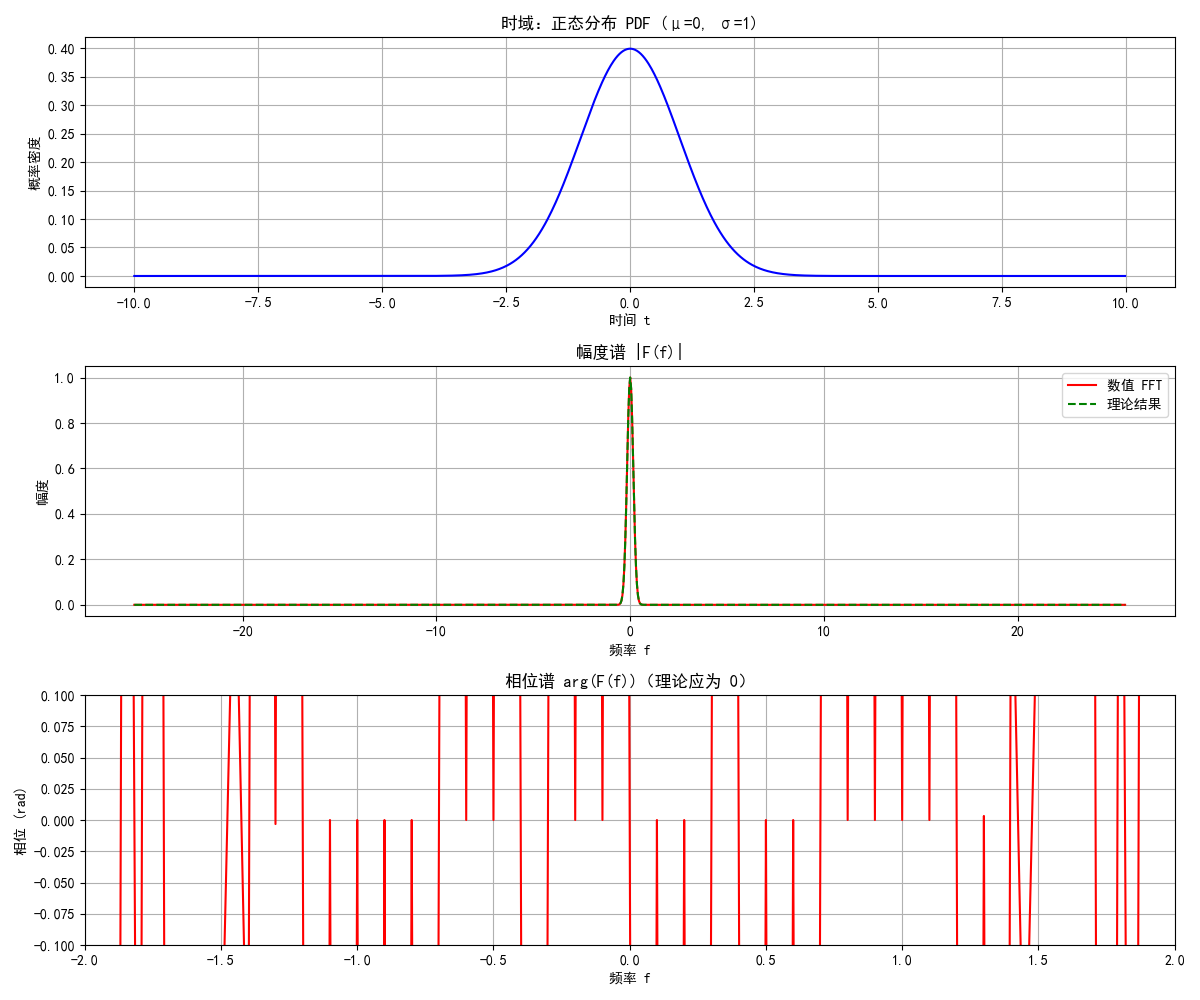

频率 (Hz)    幅度          相位 (rad)
0.0000      1.000000      0.000000
0.0500      0.951850      -3.141593
0.1000      0.820869      0.000000
0.1500      0.641381      -3.141593
0.2000      0.454041      -0.000000
0.2500      0.291213      -3.141593
0.3000      0.169225      0.000000
0.3500      0.089095      3.141593
0.4000      0.042499      0.000000
0.4500      0.018367      -3.141593


In [67]:
#验证数据：
if __name__ == "__main__":
    # 定义正态分布 PDF（均值 μ=0，标准差 σ=1）
    # 数值计算参数
    t_range = (-10, 10)   # 时间范围（覆盖正态分布主要能量）
    N = 1024              # 采样点数

    # 调用数值傅里叶变换
    # result = fourier_transform_nonperiodic(gaussian_pdf, t_range, N, return_signal=True)
    result = myFFTNonperiodic(gaussian_pdf,t_range,N,return_signal=True)
    
    # 提取频域结果（零频居中）
    f_shift = result['freq_shifted']
    amp_shift = result['amplitude_shifted']
    phase_shift = result['phase_shifted']

    # 理论幅度谱（零频居中）
    amp_theory = np.abs(gaussian_theoretical_ft(f_shift))

    # 绘图对比
    plt.figure(figsize=(12, 10))

    # 时域信号
    plt.subplot(3, 1, 1)
    plt.plot(result['t'], result['y'], 'b-') #原始的x 和原始的y
    plt.title("时域：正态分布 PDF (μ=0, σ=1)")
    plt.xlabel("时间 t")
    plt.ylabel("概率密度")
    plt.grid(True)

    # 幅度谱（数值 vs 理论）
    plt.subplot(3, 1, 2)
    plt.plot(f_shift, amp_shift, 'r-', label="数值 FFT")
    plt.plot(f_shift, amp_theory, 'g--', label="理论结果")
    plt.title("幅度谱 |F(f)|")
    plt.xlabel("频率 f")
    plt.ylabel("幅度")
    plt.legend()
    plt.grid(True)
    # plt.xlim(-2, 2)   # 主要能量集中在低频

    # 相位谱（理论应为0）
    plt.subplot(3, 1, 3)
    plt.plot(f_shift, phase_shift, 'r-')
    plt.title("相位谱 arg(F(f))（理论应为 0）")
    plt.xlabel("频率 f")
    plt.ylabel("相位 (rad)")
    plt.grid(True)
    plt.xlim(-2, 2)
    plt.ylim(-0.1, 0.1)   # 数值噪声引起的微小相位波动

    plt.tight_layout()
    plt.show()

    # 打印频率、幅度、相位示例（前10个正频率）
    pos_mask = result['freq'] >= 0
    print("频率 (Hz)    幅度          相位 (rad)")
    for f, amp, ph in zip(result['freq'][pos_mask][:10],
                          result['amplitude'][pos_mask][:10],
                          result['phase'][pos_mask][:10]):
        print(f"{f:.4f}      {amp:.6f}      {ph:.6f}")

In [ ]:
    if np.isscalar(x):
        return np.cos(2 * np.pi * x * freq + phase) @ amp
    else:
        # x 为数组，形状 (M,)
        return np.cos(2 * np.pi * x[:, None] * freq + phase) @ amp

In [14]:
rst1['fft']['freq']

array([  0.  ,   0.25,   0.5 ,   0.75,   1.  ,   1.25,   1.5 ,   1.75,
         2.  ,   2.25,   2.5 ,   2.75,   3.  ,   3.25,   3.5 ,   3.75,
         4.  ,   4.25,   4.5 ,   4.75,   5.  ,   5.25,   5.5 ,   5.75,
         6.  ,   6.25,   6.5 ,   6.75,   7.  ,   7.25,   7.5 ,   7.75,
         8.  ,   8.25,   8.5 ,   8.75,   9.  ,   9.25,   9.5 ,   9.75,
        10.  ,  10.25,  10.5 ,  10.75,  11.  ,  11.25,  11.5 ,  11.75,
        12.  ,  12.25, -12.5 ])

In [ ]:
np.cos(2 * np.pi * x[:,None] * rst1['fft']['freq'] - rst1['fft']['phase']) @ rst1['fft']['amplitude'],y

In [7]:
rst1['fft']

{'freq': array([  0.  ,   0.25,   0.5 ,   0.75,   1.  ,   1.25,   1.5 ,   1.75,
          2.  ,   2.25,   2.5 ,   2.75,   3.  ,   3.25,   3.5 ,   3.75,
          4.  ,   4.25,   4.5 ,   4.75,   5.  ,   5.25,   5.5 ,   5.75,
          6.  ,   6.25,   6.5 ,   6.75,   7.  ,   7.25,   7.5 ,   7.75,
          8.  ,   8.25,   8.5 ,   8.75,   9.  ,   9.25,   9.5 ,   9.75,
         10.  ,  10.25,  10.5 ,  10.75,  11.  ,  11.25,  11.5 ,  11.75,
         12.  ,  12.25, -12.5 ]),
 'amplitude': array([3.12630690e+00, 6.78086878e-01, 3.29815169e-02, 2.90954216e-02,
        2.64163295e-02, 2.29631269e-02, 1.99984338e-02, 1.76094312e-02,
        1.56925398e-02, 1.41387634e-02, 1.28622775e-02, 1.17994469e-02,
        1.09035099e-02, 1.01398560e-02, 9.48254293e-03, 8.91184754e-03,
        8.41256162e-03, 7.97279937e-03, 7.58315435e-03, 7.23609569e-03,
        6.92552977e-03, 6.64647774e-03, 6.39483529e-03, 6.16719140e-03,
        5.96069006e-03, 5.77292369e-03, 5.60185008e-03, 5.44572713e-03,
        5

In [3]:
x = np.linspace(1,5,99,endpoint=False)
y = x + 2*np.sin(x)
rst1 = myFFTAlgebra(x,y,T=4)
rst2 = myFFTNonperiodic(y,(1,5),100,return_signal=True)

x1 = np.linspace(4,6,10)
y1 = myPredictFromAB(x1,rst1['manual']['cos_coef'],rst1['manual']['sin_coef'],T=rst1['manual']['cycle'])
y2 = myPredictFromSeries(x1,rst1['fft']['freq'] ,rst1['fft']['amplitude'],rst1['fft']['phase'],x[0])
# y2 = myPredictFromAB(x1,rst1['fft']['cos_coef'],rst1['fft']['sin_coef'],T=rst1['fft']['cycle'])
y3 = myPredictFromComplex(rst2,x1)
# y3 = myPredictFromSeries(x,rst2['freq_shifted'],rst2['amplitude_shifted'],rst2['phase_shifted'])

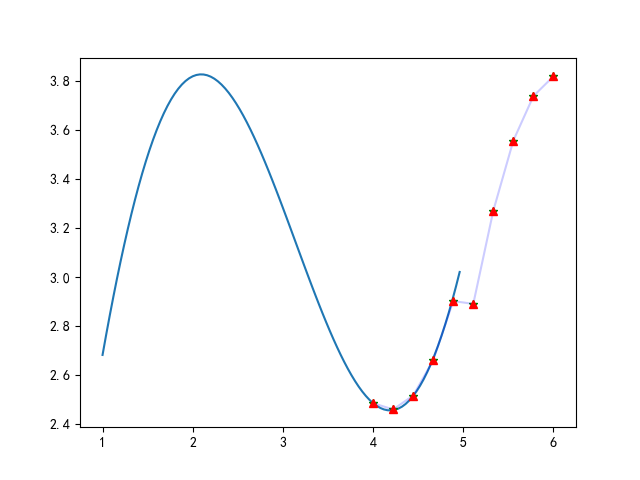

In [8]:
%matplotlib widget
plt.close('all')
fig,ax = plt.subplots()
ax.plot(x,y)
# ax.plot(x,y1,'ro')
ax.plot(x1,y1,'g*')
ax.plot(x1,y2,'b-',alpha=0.2)
ax.plot(x1,y3,'r^')


In [88]:
x = np.linspace(1,4,20)
y = gaussian_pdf(x,mu=2,sigma=1)

In [92]:
y

array([0.24197072, 0.27984786, 0.31568495, 0.34734294, 0.37276556,
       0.39019869, 0.39839011, 0.39673819, 0.38536491, 0.36510102,
       0.33738568, 0.30409757, 0.26734494, 0.22924702, 0.19173798,
       0.15641749, 0.12446155, 0.0965957 , 0.07312285, 0.05399097])

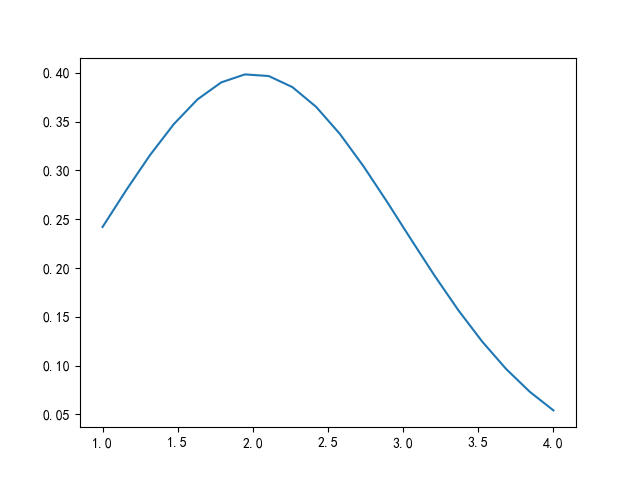

In [91]:
plt.close('all')
plt.plot(x,y)

In [85]:
p

In [ ]:
#OK，1，使用numpy的fft的进行分解，然后使用分解的结果重构函数，用于预测对应的值。

import numpy as np
import matplotlib.pyplot as plt
def myFFTAnalysis(x,y,T=None):
    """
    对周期信号进行傅里叶分析,使用numpy的FFT
    参数
    ----------
    x : 1D ndarray
        等间距采样时间点，应覆盖一个完整周期 [0, T)（不含右端点）
    y : 1D ndarray
        与 x 对应的信号值
    T : float, optional
        信号周期。若为 None，则根据 x 自动计算（假设采样均匀且区间结束于 T 之前）
    返回
    -------
    result : dict，结构如下：
      {
          'freq': ndarray,          # 正频率分量（包含直流和 Nyquist）
          'amplitude': ndarray,     # 单边幅度谱
          'phase': ndarray          # 相位（弧度，对应余弦形式 cos(2πft + φ)）
      }
    """
    x = np.asarray(x).flatten()
    y = np.asarray(y).flatten()
    N = len(x)
    if N != len(y):
        raise ValueError("x 和 y 长度必须相同")
    # 自动确定周期 T（假设采样均匀且覆盖 [0, T)）
    if T is None:
        dx = x[1] - x[0] if N > 1 else 1.0
        T = x[-1] + dx          # 最后一个采样点 + 采样间隔
    # ========== 方法1：NumPy FFT（单边谱）==========
    fft_vals = np.fft.fft(y) / N          # 双边谱（已归一化）
    freqs_fft = np.fft.fftfreq(N, d=T/N)  # 双边频率
    # 取单边正频率（0 到 Nyquist）
    pos_idx = np.arange(0, N//2 + 1)
    freqs_single = freqs_fft[pos_idx]
    fft_single = fft_vals[pos_idx]
    # 幅度：单边谱时，除直流外乘以 2
    amp_single = np.abs(fft_single)
    amp_single[1:-1] *= 2   # 对非直流且非 Nyquist 的频率的幅度加倍
    # 相位（直接来自 FFT 的辐角）
    phase_single = np.angle(fft_single)

    result = {'freq': freqs_single,  #频率
        'amplitude': amp_single,     #幅度
        'phase': phase_single,       #相位
    }
    return result
if __name__ == '__main__':
    x = np.linspace(0, 2, 64, endpoint=False)          # 32 个采样点，周期 T = 1
    y = np.sin(2 * np.pi * 2 * x) + np.sin(2 * np.pi * 3 * x + np.pi / 4) + np.sin(2 * np.pi * 5 * x)
    T = 2.0   # 明确周期
    r = myFFTAnalysis(x,y,T)
    def reCalc(x, freq, amp, phase):
        if np.isscalar(x):
            return np.cos(2 * np.pi * x * freq + phase) @ amp
        else:
            # x 为数组，形状 (M,)
            return np.cos(2 * np.pi * x[:, None] * freq + phase) @ amp
    def reCalc_ori(x):
        rst = np.cos(2*np.pi* x * r['freq'] + r['phase']) @ r['amplitude']
        return rst
    x1 = np.linspace(2, 4, 100, endpoint=False)
    # y1 = list(map(reCalc_ori,x1))
    y1 = reCalc(x1,r['freq'],r['amplitude'],r['phase'])
    

In [ ]:
#OK，2，使用代数求解的方式进行傅里叶变换，然后使用分解的结果重构函数，用于预测对应的值。

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS', 'DejaVu Sans', 'Arial', 'Liberation Sans', 'Noto Sans CJK SC']
plt.rcParams['axes.unicode_minus'] = False
def myFFTAlgebra(x, y, T=None):
    """
    对周期信号进行傅里叶分析（FFT 和手动级数两种方法）
    参数
    ----------
    x : 1D ndarray
        等间距采样时间点，应覆盖一个完整周期 [0, T)（不含右端点）
    y : 1D ndarray
        与 x 对应的信号值
    T : float, optional
        信号周期。若为 None，则根据 x 自动计算（假设采样均匀且区间结束于 T 之前）

    返回
    -------
    result : dict
        包含两种方法的结果字典，结构如下：
        {
          'fft': {
              'freq': ndarray,          # 正频率分量（包含直流和 Nyquist）
              'amplitude': ndarray,     # 单边幅度谱
              'phase': ndarray          # 相位（弧度，对应余弦形式 cos(2πft + φ)）
          },
          'manual': {
              'freq': ndarray,          # 频率（k/T）
              'amplitude': ndarray,     # 幅度 sqrt(a_k² + b_k²)
              'phase': ndarray,         # 相位 arctan2(-b_k, a_k)
              'cos_coef': ndarray,      # 余弦系数 a_k（k=0,1,...,Nyquist）
              'sin_coef': ndarray,      # 正弦系数 b_k（b_0 = 0, b_Nyquist = 0）
              'reconstructed': ndarray  # 使用 a,b 重建的信号
          }
        }
    """
    x = np.asarray(x).flatten()
    y = np.asarray(y).flatten()
    N = len(x)
    if N != len(y):
        raise ValueError("x 和 y 长度必须相同")

    # 自动确定周期 T（假设采样均匀且覆盖 [0, T)）
    if T is None:
        dx = x[1] - x[0] if N > 1 else 1.0
        T = x[-1] + dx          # 最后一个采样点 + 采样间隔


    # ========== 方法2：手动傅里叶级数系数 ==========
    # 确定最高谐波次数
    if N % 2 == 1:          # 奇数个点，最高谐波 (N-1)/2
        K = (N - 1) // 2
        nyquist = False
    else:                   # 偶数个点，最高谐波 N/2 (Nyquist)
        K = N // 2
        nyquist = True

    a = np.zeros(K + 1)     # cos 系数
    b = np.zeros(K + 1)     # sin 系数

    for k in range(K + 1):
        if k == 0:
            a[k] = np.mean(y)          # 直流分量 = 平均值
            b[k] = 0.0
        elif nyquist and k == K:       # Nyquist 频率（只有余弦项）
            a[k] = (1.0 / N) * np.sum(y * np.cos(2 * np.pi * k * x / T))
            b[k] = 0.0
        else:
            a[k] = (2.0 / N) * np.sum(y * np.cos(2 * np.pi * k * x / T))
            b[k] = (2.0 / N) * np.sum(y * np.sin(2 * np.pi * k * x / T))

    freqs_manual = np.arange(K + 1) / T
    # 幅度与相位（余弦形式：a cos + b sin = A cos(2πft + φ)）
    amp_manual = np.sqrt(a**2 + b**2)
    phase_manual = np.arctan2(-b, a)   # 注意负号，使得 cos(2πft + φ) 展开为 a cos - b sin
    # 重建信号
    

    # ========== 输出结果 ==========
    result = {
        'freq': freqs_manual,
        'amplitude': amp_manual,
        'phase': phase_manual,
        'cos_coef': a,
        'sin_coef': b,
        'cycle':T,
        'K':K
    }
    return result

def reCalcAB(x,a,b,T=None,K=None):
    y_recon = np.zeros_like(x)
    
    for i, t in enumerate(x):
        for k in range(K + 1):
            y_recon[i] += a[k] * np.cos(2 * np.pi * k * t / T) + b[k] * np.sin(2 * np.pi * k * t / T)
    return y_recon

# ----------------- 测试：使用您原来的信号 -----------------
if __name__ == "__main__":
    # 生成与原始代码完全相同的测试信号
    x = np.linspace(0, 2, 64, endpoint=False)          # 32 个采样点，周期 T = 1
    y = np.sin(2 * np.pi * 2 * x) + np.sin(2 * np.pi * 3 * x + np.pi / 4) + 2*np.sin(2 * np.pi * 5 * x)
    T = 2.0   # 明确周期

    res = myFFTAlgebra(x, y, T)
    y_hat = reCalcAB(x,res['cos_coef'],res['sin_coef'],res['cycle'],res['K'])

    print("=== FFT 方法（前 8 个频率）===")
    # for f, amp, ph in zip(res['fft']['freq'][:8], res['fft']['amplitude'][:8], res['fft']['phase'][:8]):
    #     print(f"频率 {f:.3f} Hz, 幅度 {amp:.4f}, 相位 {ph:.4f} rad")

    print("\n=== 手动级数方法（前 8 个频率）===")
    for f, amp, ph, a, b in zip(res['freq'][:8],
                                 res['amplitude'][:8],
                                 res['phase'][:8],
                                 res['cos_coef'][:8],
                                 res['sin_coef'][:8]):
        print(f"频率 {f:.3f} Hz, 幅度 {amp:.4f}, 相位 {ph:.4f} rad, a={a:.4f}, b={b:.4f}")

    # 验证重建误差
    print("\n手动级数重建信号与原始信号的最大绝对误差：",
          np.max(np.abs(y_hat - y)))

    # 绘图对比（可选）
    # plt.figure(figsize=(12, 5))
    # plt.subplot(1, 2, 1)
    # plt.stem(res['fft']['freq'], res['fft']['amplitude'], basefmt=" ")
    # plt.title("FFT 单边幅度谱")
    # plt.xlabel("频率 (Hz)")
    # plt.ylabel("幅度")
    # plt.grid(True)

    # plt.subplot(1, 2, 2)
    plt.subplot(1, 1, 1)
    plt.stem(res['freq'], res['amplitude'], basefmt=" ")
    plt.title("手动级数幅度谱")
    plt.xlabel("频率 (Hz)")
    plt.ylabel("幅度")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
# OK，3，使用傅里叶矩阵进行傅里叶分解：
import numpy as np
import matplotlib.pyplot as plt

def fourier_analysis_matrix(y, T=None):
    """
    使用傅里叶矩阵（最小二乘法）对周期信号进行傅里叶级数分解。
    返回频率、幅度、相位，以及余弦系数 a 和正弦系数 b。

    参数
    ----------
    y : np.ndarray
        一维信号数组，假设在区间 [0, T) 上等间距采样（不含右端点）。
    T : float, optional
        信号周期。若为 None，则 T = len(y)（采样间隔为 1）。

    返回
    -------
    result : dict
        {
            'freq': ndarray,          # 频率数组 [0, 1/T, 2/T, ..., K/T]
            'amplitude': ndarray,     # 幅度谱（单边，对应余弦形式 A*cos(2πft + φ)）
            'phase': ndarray,         # 相位谱（弧度，范围 -π 到 π）
            'cos_coef': ndarray,      # 余弦系数 a_k（k=0,1,...,K）
            'sin_coef': ndarray,      # 正弦系数 b_k（k=0,1,...,K，其中 b_0=0，Nyquist 处 b=0）
            'reconstructed': ndarray, # 使用系数重建的信号
        }
    """
    y = np.asarray(y).flatten()
    N = len(y)
    if T is None:
        T = float(N)          # 默认周期等于采样点数（采样间隔为1）
    # 等间距时间点（不包含右端点，保证周期性）
    x = np.linspace(0, T, N, endpoint=False)
    w = 2 * np.pi / T         # 基频

    # 确定傅里叶级数的最高次数 K
    if N % 2 == 1:            # 奇数个点
        K = (N - 1) // 2
        cos_freqs = np.arange(0, K + 1)          # 0,1,...,K
        sin_freqs = np.arange(1, K + 1)          # 1,2,...,K
    else:                     # 偶数个点
        K = N // 2
        cos_freqs = np.arange(0, K + 1)          # 0,1,...,K
        sin_freqs = np.arange(1, K)              # 1,2,...,K-1

    # 构造傅里叶矩阵 mat
    mat = np.empty((N, 0))
    for k in cos_freqs:
        mat = np.column_stack((mat, np.cos(k * w * x)))
    for k in sin_freqs:
        mat = np.column_stack((mat, np.sin(k * w * x)))

    # 最小二乘法求解系数（mat 是方阵时等价于线性方程组求解）
    # 使用 lstsq 更稳定，但原代码用 inv，这里保留原风格也可，改为 lstsq 更鲁棒
    c, _, _, _ = np.linalg.lstsq(mat, y, rcond=None)   # 系数向量

    # 分离余弦系数 a 和正弦系数 b（注意长度可能不同）
    a_raw = c[:len(cos_freqs)]        # 对应 cos_freqs 顺序
    b_raw = c[len(cos_freqs):]        # 对应 sin_freqs 顺序

    # 构造完整的 a_k, b_k 数组（k = 0 .. K）
    a_full = np.zeros(K + 1)
    b_full = np.zeros(K + 1)

    # 填充余弦系数
    for idx, k in enumerate(cos_freqs):
        a_full[k] = a_raw[idx]
    # 填充正弦系数（sin_freqs 中的 k 从 1 开始）
    for idx, k in enumerate(sin_freqs):
        b_full[k] = b_raw[idx]

    # 频率数组
    freqs = np.arange(K + 1) / T

    # 幅度和相位（余弦形式：A cos(2πft + φ) = a cos(2πft) + b sin(2πft)）
    # 关系：a = A cos φ, b = -A sin φ  => A = sqrt(a²+b²), φ = atan2(-b, a)
    amplitude = np.sqrt(a_full**2 + b_full**2)
    phase = np.arctan2(-b_full, a_full)   # 范围 [-π, π]

    # 重建信号（使用完整级数）
    y_recon = mat @ c

    # 结果字典
    result = {
        'freq': freqs,
        'amplitude': amplitude,
        'phase': phase,
        'cos_coef': a_full,
        'sin_coef': b_full,
        'reconstructed': y_recon,
    }
    return result

def reCalcMat(x,a,b,T=None,K=None):
    y_recon = np.zeros_like(x)
    for i, t in enumerate(x):
        for k in range(K + 1):
            y_recon[i] += a[k] * np.cos(2 * np.pi * k * t / T) + b[k] * np.sin(2 * np.pi * k * t / T)
    return y_recon
# ----------------- 测试：使用原代码中的数据 -----------------
if __name__ == "__main__":
    # 原代码中的数据构造（周期 T=8，采样点数 N=21）
    x_orig = np.linspace(-2, 2, 11)
    y_orig = np.cos(x_orig) + 2 * np.sin(2 * x_orig)
    t = ((x_orig + 2) * -1)[::-1]
    x_full = np.hstack((t[0:-1], x_orig + 2))
    y_full = np.hstack((y_orig[::-1][0:-1], y_orig))

    T = 8.0   # 已知周期

    res = fourier_analysis_matrix(y_full, T)

    print("频率 (Hz)：", res['freq'])
    print("幅度：", res['amplitude'])
    print("相位 (rad)：", res['phase'])
    print("余弦系数 a：", res['cos_coef'])
    print("正弦系数 b：", res['sin_coef'])
    print("\n重建信号与原始信号的最大绝对误差：", np.max(np.abs(res['reconstructed'] - y_full)))

    # 可选：绘制幅度谱和相位谱
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.stem(res['freq'], res['amplitude'], basefmt=" ")
    plt.title("幅度谱 (傅里叶矩阵法)")
    plt.xlabel("频率 (Hz)")
    plt.ylabel("幅度")
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.stem(res['freq'], res['phase'], basefmt=" ")
    plt.title("相位谱 (傅里叶矩阵法)")
    plt.xlabel("频率 (Hz)")
    plt.ylabel("相位 (rad)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [141]:
y1 = myPredictFromComplex(result,t)

In [166]:
result = myFFTNonperiodic(func,(1,5),200,return_signal=True)

In [114]:
def func(x):
    return x + 2 * np.sin(x)

t_start, t_end = (1,5)
N = 200
t = np.linspace(t_start, t_end, N, endpoint=False)
dt = t[1] - t[0]   # 采样间隔

# 生成信号
if callable(func):
    y = func(t)
else:
    y = np.asarray(func).flatten()
    if len(y) != N:
        raise ValueError("如果直接传入信号数组，其长度必须等于 N")

# 执行 FFT
Y = fft(y) * dt          # 乘以 dt 近似连续傅里叶变换积分
freqs = fftfreq(N, dt)   # 双边频率（负频在前，正频在后）
# freqs = fftfreq(N, dt)   # 双边频率（负频在前，正频在后）

# 计算幅度、相位、实部、虚部
amplitude = np.abs(Y)
phase = np.angle(Y)
real = np.real(Y)
imag = np.imag(Y)

# fftshift：将零频移到中心
freqs_shifted = fftshift(freqs)
amplitude_shifted = fftshift(amplitude)
phase_shifted = fftshift(phase)


#逆向还原：
# f = ft_result['freq']
f = freqs
# 复频谱 F(f)
# if 'real' in ft_result and 'imag' in ft_result:
#     F = ft_result['real'] + 1j * ft_result['imag']
# elif 'amplitude' in ft_result and 'phase' in ft_result:
#     F = ft_result['amplitude'] * np.exp(1j * ft_result['phase'])
# else:
#     raise KeyError("ft_result 必须包含 ('real','imag') 或 ('amplitude','phase') 字段")
F = real + 1j * imag

# 频率分辨率 Δf
# df = f[1] - f[0]   # 假设频率等间隔
df = 1 / (N * dt)


# 将 t_points 转换为数组
# t_vals = np.atleast_1d(t_points)
t_vals = np.atleast_1d(t)
# y_vals = np.zeros_like(t_vals, dtype=float)
y_vals = np.zeros_like(t_vals, dtype=complex)

# 对每个时间点求和：y(t) ≈ Σ F(f_k) * exp(j 2π f_k t) * Δf
for i, h in enumerate(t_vals):
    # 注意：由于 F 是双边谱，直接使用全部频率积分即可
    # y_vals[i] = np.sum(F * np.exp(1j * 2 * np.pi * f * h)) * df
    y_vals[i] = np.sum(F * np.exp(1j * 2 * np.pi * f * h)) * df
# 理论上结果应为实数（因为原信号是实函数），取实部
y_vals = np.real(y_vals)



(200,)

In [168]:
t1 = np.linspace(4,7,50,endpoint=False)

In [169]:
y1 = myPredictFromComplex(result,t1)

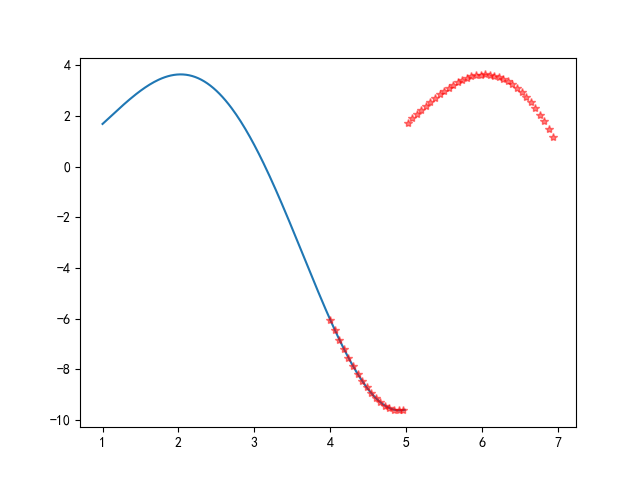

In [170]:
%matplotlib widget
plt.close('all')

fig,ax = plt.subplots()
ax.plot(result['t'],result['y'])
ax.plot(t1,y1,'r*',alpha=0.5)

In [148]:
import numpy as np
from numpy.fft import fft, fftfreq

def func(x):
    return x * 2 * np.sin(x)

t_start, t_end = (1,4)
N = 200
t = np.linspace(t_start, t_end, N, endpoint=False)
dt = t[1] - t[0]

# 原始信号
y = func(t)

# ==================== 连续傅里叶 正变换（你原来的写法）====================
Y = fft(y) * dt          # 必须乘 dt
freqs = fftfreq(N, dt)   # 频率轴
F = np.real(Y) + 1j * np.imag(Y)
df = freqs[1] - freqs[0] # 正确 df

# ==================== 连续傅里叶 逆变换（唯一正确写法）====================
y_vals = np.zeros_like(t, dtype=complex)
t0 = t[0]  # 时间起点偏移（关键！）

for i, ti in enumerate(t):
    # 1. 指数用 +1j ✔️
    # 2. 时间必须减去起始偏移 ti - t0 ✔️
    # 3. 逆变换必须乘 df ✔️
    y_vals[i] = np.sum(F * np.exp(1j * 2 * np.pi * freqs * (ti - t0))) * df

# 原信号是实数，取实部
y_vals = np.real(y_vals)

# 看结果！
print("最大误差：", np.max(np.abs(y_vals - y)))

最大误差： 6.631140081481135e-12


In [132]:
import numpy as np
from numpy.fft import fft, fftfreq

def func(x):
    return x * 2 * np.sin(x)

t_start, t_end = (1, 4)
N = 200
t = np.linspace(t_start, t_end, N, endpoint=False)
dt = t[1] - t[0]

y = func(t)

# FFT
Y = fft(y)
freqs = fftfreq(N, dt)

# ================= 核心修复 =================
# 时间偏移补偿（你时间从1开始，不是从0开始！）
t0 = t[0]  # = 1

y_vals = np.zeros_like(t, dtype=complex)
for i, ti in enumerate(t):
    val = np.sum(Y * np.exp(-1j * 2 * np.pi * freqs * (ti - t0))) / N
    y_vals[i] = val

y_vals = np.real(y_vals)

print("最大误差：", np.max(np.abs(y_vals - y)))

最大误差： 7.677342687841623


In [134]:
import numpy as np
from numpy.fft import fft, ifft, fftfreq, fftshift

def func(x):
    return x * 2 * np.sin(x)

t_start, t_end = (1,4)
N = 200
t = np.linspace(t_start, t_end, N, endpoint=False)
dt = t[1] - t[0]

y = func(t)

# ==================== 修复 1：正变换不要乘 dt！====================
Y = fft(y)  # 这里去掉 *dt
freqs = fftfreq(N, dt)

F = np.real(Y) + 1j * np.imag(Y)

# ==================== 修复 2：逆变换必须除以 N ====================
y_vals = np.zeros_like(t, dtype=complex)
for i, h in enumerate(t):
    y_vals[i] = np.sum(F * np.exp(1j * 2 * np.pi * freqs * h)) / N

# 取实部
y_vals = np.real(y_vals)

# 测试
print("最大误差：", np.max(np.abs(y_vals - y)))

最大误差： 9.577427722115573
